# Online Retail Data Cleaning and Exploratory Data Analysis

## Project Overview

This project analyzes transactional data from an online retail store. The goal is to clean and preprocess the raw dataset, explore sales patterns, and identify useful insights about customers, products, and revenue.

### Objectives

- Inspect and understand the dataset
- Identify and handle missing or invalid data
- Clean and preprocess transaction records
- Perform exploratory data analysis (EDA)
- Visualize important sales patterns
- Identify key business insights

## 1. Import Libraries


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## 2. Load the Dataset

In [2]:
df = pd.read_excel("data/online_retail_II.xlsx")

In [3]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


## 3. Initial Data Exploration

Before cleaning the dataset, we first examine its structure, size, data types, missing values, and basic descriptive statistics.

In [4]:
df.shape

(525461, 8)

In [5]:
df.columns

Index(['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'Price', 'Customer ID', 'Country'],
      dtype='str')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 525461 entries, 0 to 525460
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      525461 non-null  object        
 1   StockCode    525461 non-null  object        
 2   Description  522533 non-null  object        
 3   Quantity     525461 non-null  int64         
 4   InvoiceDate  525461 non-null  datetime64[us]
 5   Price        525461 non-null  float64       
 6   Customer ID  417534 non-null  float64       
 7   Country      525461 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 32.1+ MB


In [7]:
df.isnull().sum()

Invoice             0
StockCode           0
Description      2928
Quantity            0
InvoiceDate         0
Price               0
Customer ID    107927
Country             0
dtype: int64

In [8]:
df.describe()

,Quantity,InvoiceDate,Price,Customer ID
count,525461.000000,525461,525461.000000,417534.000000
mean,10.337667,2010-06-28 11:37:36.845018,4.688834,15360.645478
min,-9600.000000,2009-12-01 07:45:00,-53594.360000,12346.000000
25%,1.000000,2010-03-21 12:20:00,1.250000,13983.000000
50%,3.000000,2010-07-06 09:51:00,2.100000,15311.000000
75%,10.000000,2010-10-15 12:45:00,4.210000,16799.000000
max,19152.000000,2010-12-09 20:01:00,25111.090000,18287.000000
std,107.424110,NaN,146.126914,1680.811316


## 4. Data Quality Assessment

The initial exploration revealed several potential data quality issues:

- Missing values are present in the `Description` and `Customer ID` columns.
- Some transactions contain negative or zero quantities.
- Some records contain negative or zero prices.
- Potential duplicate transaction records may be present.
- Extreme values in `Quantity` and `Price` require further investigation.

These issues will be examined before deciding how to clean the dataset.

### 4.1 Invalid and Negative Quantities

In [9]:
df[df["Quantity"] <= 0].head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
183,C489449,21871,SAVE THE PLANET MUG,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,2009-12-01 10:33:00,0.85,16321.0,Australia
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3,2009-12-01 10:44:00,4.25,17592.0,United Kingdom


In [10]:
(df["Quantity"] <= 0).sum()

np.int64(12326)

### 4.2 Invalid and Non-Positive Prices

In [11]:
df[df["Price"] <= 0].head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.0,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom
3161,489659,21350,NaN,230,2009-12-01 17:39:00,0.0,NaN,United Kingdom
3162,489660,35956,lost,-1043,2009-12-01 17:43:00,0.0,NaN,United Kingdom
3168,489663,35605A,damages,-117,2009-12-01 18:02:00,0.0,NaN,United Kingdom
3731,489781,84292,NaN,17,2009-12-02 11:45:00,0.0,NaN,United Kingdom
4296,489806,18010,NaN,-770,2009-12-02 12:42:00,0.0,NaN,United Kingdom


In [12]:
(df["Price"] <= 0).sum()

np.int64(3690)

### 4.3 Duplicate Records

In [13]:
df.duplicated().sum()

np.int64(6865)

### 4.4 Missing Values

In [14]:
missing_values = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percentage": (df.isnull().sum() / len(df) * 100).round(2)
})

missing_values

,Missing Values,Percentage
Invoice,0,0.00
StockCode,0,0.00
Description,2928,0.56
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Customer ID,107927,20.54
Country,0,0.00


## 5. Data Cleaning

Based on the data quality assessment, the dataset is cleaned by removing duplicate records, separating cancelled transactions from completed sales, filtering invalid prices and quantities, and handling missing values according to the requirements of the analysis.

In [15]:
df_clean = df.copy()

### 5.1 Remove Duplicate Records

In [16]:
df_clean = df_clean.drop_duplicates()

In [17]:
df_clean.duplicated().sum()

np.int64(0)

In [18]:
df_clean.shape

(518596, 8)

### 5.2 Identify Cancelled Transactions

In [19]:
cancelled = df_clean[
    df_clean["Invoice"].astype(str).str.startswith("C")
]

cancelled.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia


In [20]:
len(cancelled)

10182

### 5.3 Create a Dataset of Valid Sales

In [21]:
sales = df_clean[
    (~df_clean["Invoice"].astype(str).str.startswith("C")) &
    (df_clean["Quantity"] > 0) &
    (df_clean["Price"] > 0)
].copy()

In [22]:
sales.shape

(504730, 8)

In [23]:
sales[["Quantity", "Price"]].describe()

,Quantity,Price
count,504730.000000,504730.000000
mean,11.516944,4.273960
std,87.337583,64.091288
min,1.000000,0.001000
25%,1.000000,1.250000
50%,3.000000,2.100000
75%,12.000000,4.210000
max,19152.000000,25111.090000


In [24]:
sales.isnull().sum()

Invoice             0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
Price               0
Customer ID    103814
Country             0
dtype: int64

## 6. Feature Engineering

Additional features are created from the existing transaction data to support sales and time-based analysis.

### 6.1 Calculate Revenue

In [25]:
sales["Revenue"] = sales["Quantity"] * sales["Price"]

In [26]:
sales[["Quantity", "Price", "Revenue"]].head()

,Quantity,Price,Revenue
0,12,6.95,83.4
1,12,6.75,81.0
2,12,6.75,81.0
3,48,2.10,100.8
4,24,1.25,30.0


### 6.2 Extract Date Features

In [27]:
sales["Year"] = sales["InvoiceDate"].dt.year
sales["Month"] = sales["InvoiceDate"].dt.month
sales["Day"] = sales["InvoiceDate"].dt.day
sales["Hour"] = sales["InvoiceDate"].dt.hour
sales["DayOfWeek"] = sales["InvoiceDate"].dt.day_name()

In [28]:
sales[
    ["InvoiceDate", "Year", "Month", "Day", "Hour", "DayOfWeek"]
].head()

,InvoiceDate,Year,Month,Day,Hour,DayOfWeek
0,2009-12-01 07:45:00,2009,12,1,7,Tuesday
1,2009-12-01 07:45:00,2009,12,1,7,Tuesday
2,2009-12-01 07:45:00,2009,12,1,7,Tuesday
3,2009-12-01 07:45:00,2009,12,1,7,Tuesday
4,2009-12-01 07:45:00,2009,12,1,7,Tuesday


In [29]:
sales.info()

<class 'pandas.DataFrame'>
Index: 504730 entries, 0 to 525460
Data columns (total 14 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      504730 non-null  object        
 1   StockCode    504730 non-null  object        
 2   Description  504730 non-null  object        
 3   Quantity     504730 non-null  int64         
 4   InvoiceDate  504730 non-null  datetime64[us]
 5   Price        504730 non-null  float64       
 6   Customer ID  400916 non-null  float64       
 7   Country      504730 non-null  str           
 8   Revenue      504730 non-null  float64       
 9   Year         504730 non-null  int32         
 10  Month        504730 non-null  int32         
 11  Day          504730 non-null  int32         
 12  Hour         504730 non-null  int32         
 13  DayOfWeek    504730 non-null  str           
dtypes: datetime64[us](1), float64(3), int32(4), int64(1), object(3), str(2)
memory usage: 50.1+ MB


## 7. Exploratory Data Analysis

This section explores the cleaned transaction data to identify sales patterns, top-performing products, geographic trends, and changes in revenue over time.

### 7.1 Overall Sales Performance

In [30]:
total_revenue = sales["Revenue"].sum()
total_orders = sales["Invoice"].nunique()
total_products = sales["StockCode"].nunique()
total_customers = sales["Customer ID"].nunique()

print(f"Total Revenue: £{total_revenue:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Unique Products: {total_products:,}")
print(f"Unique Customers: {total_customers:,}")

Total Revenue: £10,271,762.66
Total Orders: 20,951
Unique Products: 4,251
Unique Customers: 4,312


### 7.2 Top-Selling Products

In [31]:
top_products = (
    sales.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products

Description
WHITE HANGING HEART T-LIGHT HOLDER    58691
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54947
BROCADE RING PURSE                    48374
PACK OF 72 RETRO SPOT CAKE CASES      46728
ASSORTED COLOUR BIRD ORNAMENT         45228
60 TEATIME FAIRY CAKE CASES           36348
PACK OF 60 PINK PAISLEY CAKE CASES    31805
JUMBO BAG RED RETROSPOT               30746
SMALL POPCORN HOLDER                  29773
STRAWBERRY CERAMIC TRINKET BOX        27059
Name: Quantity, dtype: int64

### 7.3 Products by Revenue

In [32]:
top_products_revenue = (
    sales.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products_revenue

Description
Manual                                 262589.86
REGENCY CAKESTAND 3 TIER               169912.76
WHITE HANGING HEART T-LIGHT HOLDER     160345.63
DOTCOM POSTAGE                         116408.71
ASSORTED COLOUR BIRD ORNAMENT           72890.19
PAPER CHAIN KIT 50'S CHRISTMAS          58127.30
JUMBO BAG RED RETROSPOT                 56480.46
PARTY BUNTING                           49664.12
POSTAGE                                 49477.54
ROTATING SILVER ANGELS T-LIGHT HLDR     47954.49
Name: Revenue, dtype: float64

### 7.4 Revenue by Country

In [33]:
revenue_by_country = (
    sales.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

revenue_by_country.head(10)

Country
United Kingdom    8812311.833
EIRE               380909.570
Netherlands        268784.350
Germany            202025.391
France             147103.140
Sweden              53501.990
Denmark             50906.850
Spain               47568.650
Switzerland         43921.390
Australia           31446.800
Name: Revenue, dtype: float64

### 7.5 Monthly Revenue

In [34]:
sales["YearMonth"] = sales["InvoiceDate"].dt.to_period("M")

In [35]:
monthly_revenue = (
    sales.groupby("YearMonth")["Revenue"]
    .sum()
)

monthly_revenue

YearMonth
2009-12     822483.950
2010-01     651155.112
2010-02     551504.726
2010-03     830915.261
2010-04     678875.252
2010-05     657705.500
2010-06     749537.310
2010-07     648810.270
2010-08     695251.910
2010-09     921696.991
2010-10    1161902.220
2010-11    1464293.142
2010-12     437631.020
Freq: M, Name: Revenue, dtype: float64

## 8. Data Visualization

The following visualizations highlight the main sales patterns identified during the exploratory analysis.

### 8.1 Top 10 Products by Quantity Sold

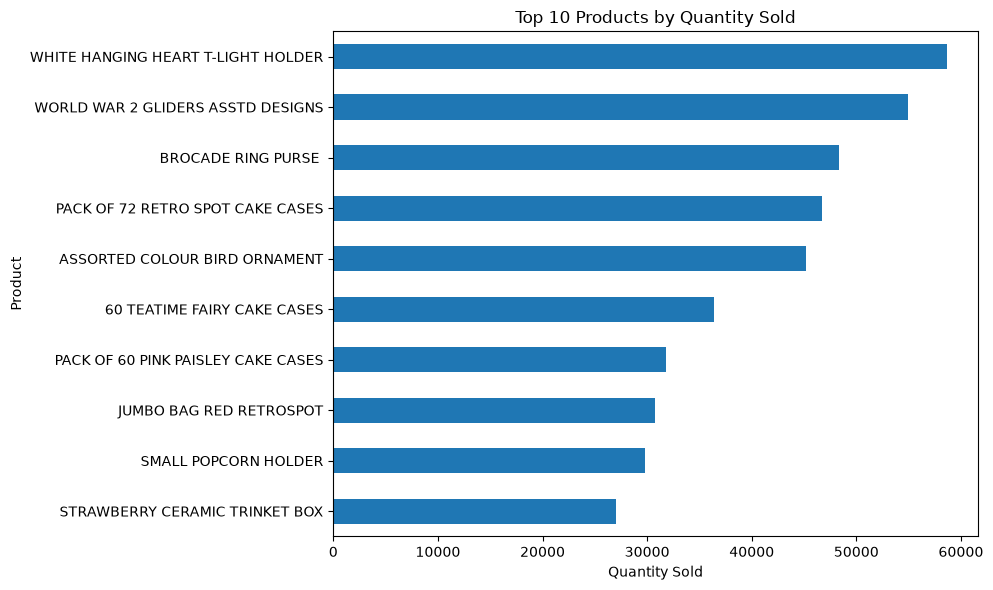

In [36]:
plt.figure(figsize=(10, 6))

top_products.sort_values().plot(kind="barh")

plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Quantity Sold")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

### 8.2 Top 10 International Markets by Revenue

The United Kingdom dominates total revenue, so it is excluded from this visualization to provide a clearer comparison of international markets.

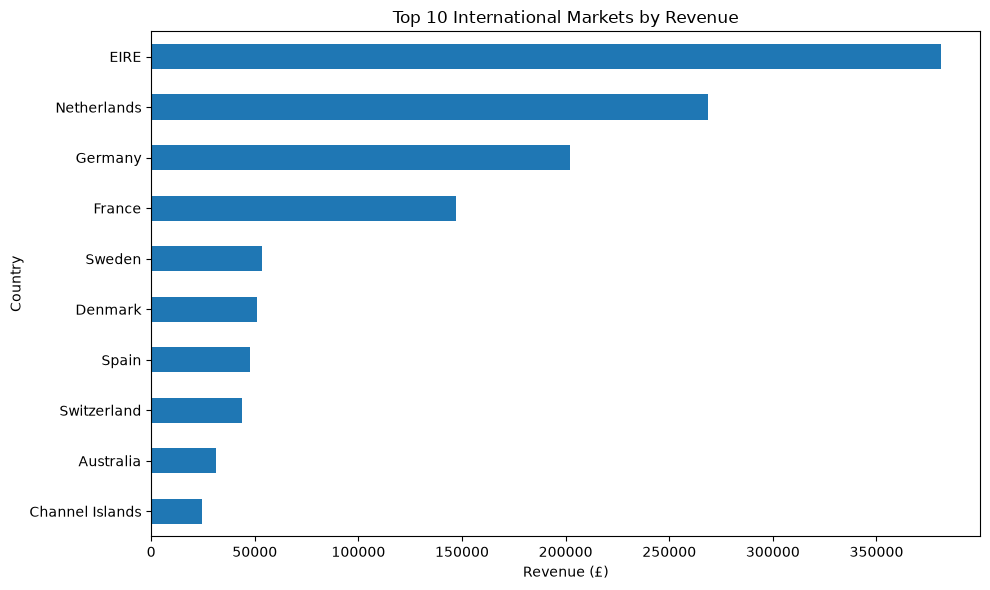

In [37]:
international_revenue = (
    revenue_by_country
    .drop("United Kingdom", errors="ignore")
    .head(10)
)

plt.figure(figsize=(10, 6))

international_revenue.sort_values().plot(kind="barh")

plt.title("Top 10 International Markets by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

### 8.3 Monthly Revenue Trend

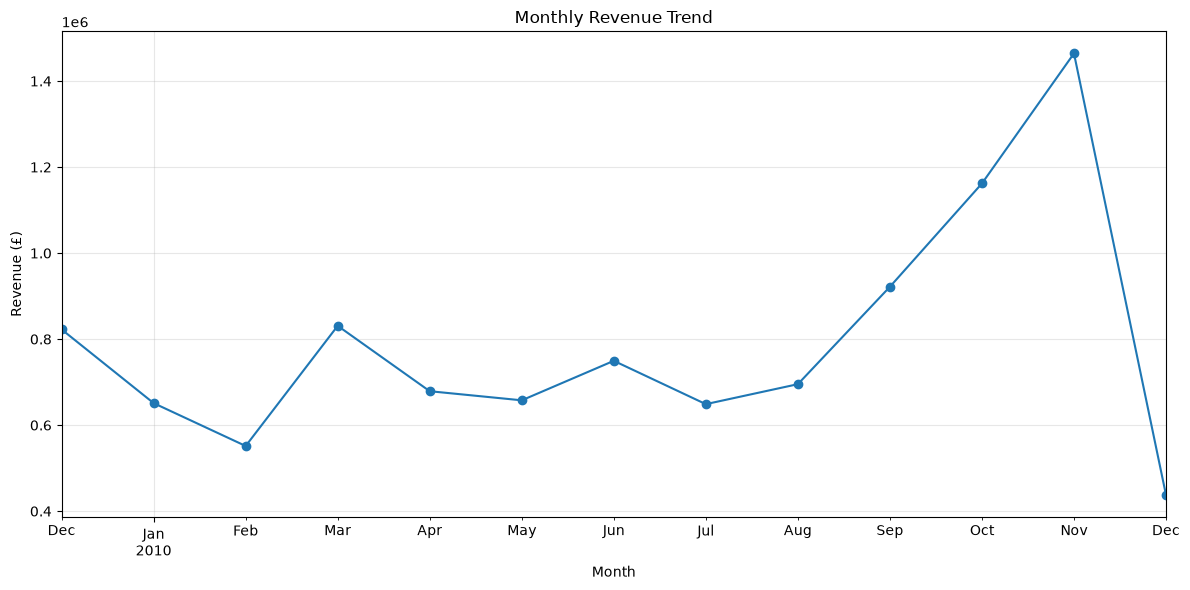

In [38]:
plt.figure(figsize=(12, 6))

monthly_revenue.plot(marker="o")

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 8.4 Revenue by Day of Week

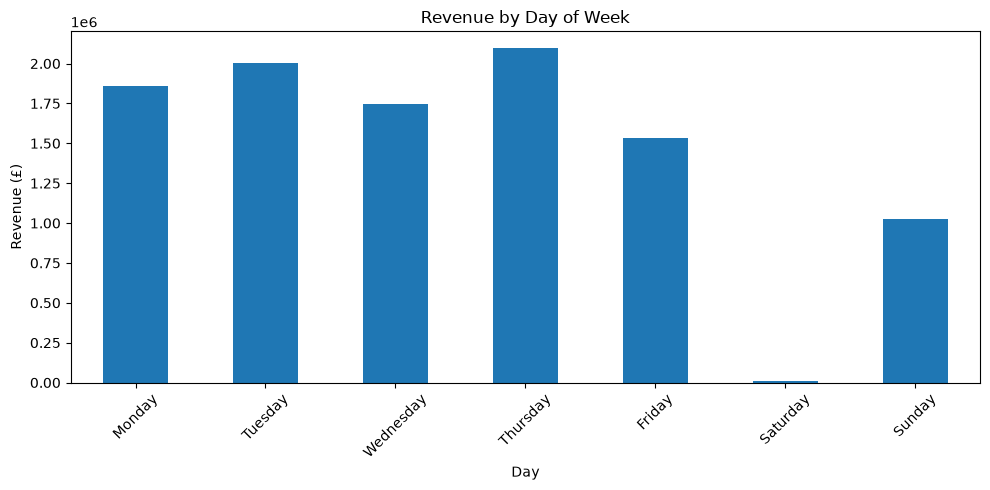

In [39]:
day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

revenue_by_day = (
    sales.groupby("DayOfWeek")["Revenue"]
    .sum()
    .reindex(day_order)
)

plt.figure(figsize=(10, 5))

revenue_by_day.plot(kind="bar")

plt.title("Revenue by Day of Week")
plt.xlabel("Day")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 9. Key Findings

The analysis revealed several important patterns in the online retail data:

- The cleaned sales dataset contains 504,730 transaction records representing 20,951 unique orders.
- Total revenue from valid sales was approximately £10.27 million.
- The dataset contains 4,251 unique products and 4,312 identified customers.
- `WHITE HANGING HEART T-LIGHT HOLDER` was the best-selling product by quantity, with 58,691 units sold.
- The United Kingdom was by far the largest market, generating approximately £8.81 million in revenue.
- Among international markets, Ireland (EIRE), the Netherlands, Germany, and France generated the highest revenue.
- Monthly revenue increased substantially during September, October, and November 2010, with November producing the highest monthly revenue.
- December 2010 contains only partial-month data and therefore should not be directly compared with complete months.
- Some of the highest-revenue descriptions, such as `Manual`, `DOTCOM POSTAGE`, and `POSTAGE`, appear to represent service or adjustment entries rather than ordinary retail products and should be interpreted separately from product performance.

## 10. Conclusion

This project demonstrated a complete data analysis workflow, from inspecting and cleaning raw transactional data to feature engineering, exploratory analysis, and visualization.

Duplicate records, cancelled transactions, invalid quantities, and non-positive prices were identified and handled before analyzing completed sales. Missing customer identifiers were retained where they did not prevent sales-level analysis, avoiding unnecessary loss of transaction data.

The final analysis highlighted the store's strongest products, major international markets, and changes in revenue over time. The results also demonstrate the importance of interpreting unusual transaction records and incomplete time periods before drawing business conclusions.

In [40]:
sales.to_csv("data/online_retail_cleaned.csv", index=False)